# Miller et al. (2020) — Canagliflozin lifespan

[Miller et al., *JCI Insight* (2020)](https://doi.org/10.1172/jci.insight.140019) · [ITP data](https://phenome.jax.org/projects/ITP1)

UM-HET3 mice, Cana 180 ppm from month 7; sites: TJL, UM, UT. Reproduced: Figures 1, 3 and Tables 1, 2. Figures 2, 4 and supplemental measurements lack individual source data. Additional analyses appear after the paper sections.


## Inputs

```bash
uv add jupyter pandas openpyxl numpy scipy matplotlib lifelines statsmodels
```

`Lifespan_C2016.xlsx` and `BodyWeight_C2016.xlsx` (sheet `Data`) in the working directory. The weight file is derived from MPD JSON data.


In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import KaplanMeierFitter
from scipy.stats import fisher_exact, ttest_ind
from statsmodels.duration.survfunc import survdiff

LIFESPAN_FILE = Path("Lifespan_C2016.xlsx")
WEIGHT_FILE = Path("BodyWeight_C2016.xlsx")
GROUPS = ("Control", "Cana")
SITES = ("TJL", "UM", "UT")
SEXES = ("f", "m")

## 1. Survival data

Each row is one mouse: `age` is age at death or censoring; `dead=1` means death, `dead=0` means censored (removed from observation).


In [5]:
life = pd.read_excel(LIFESPAN_FILE)
survival = life.loc[
    life["group"].isin(GROUPS),
    ["site", "sex", "group", "age", "dead"],
].copy()

survival.groupby(["sex", "site", "group"]).agg(
    animals=("age", "size"),
    observed_deaths=("dead", "sum"),
)

animals  observed_deaths
sex site group                            
f   TJL  Cana          48               48
         Control       96               95
    UM   Cana          44               44
         Control       92               92
    UT   Cana          44               44
         Control      116              116
m   TJL  Cana          54               53
         Control      102               94
    UM   Cana          51               41
         Control      102               82
    UT   Cana          51               51
         Control       99               99

## 2. Figure 1 — Kaplan–Meier curves

$$
\hat S(t)=\prod_{t_i\leq t}\left(1-\frac{d_i}{n_i}\right)
$$

$d_i$: deaths at age $t_i$; $n_i$: mice at risk. Dots mark **every death** (tied events overlap). Blue Control is layered above orange Cana.


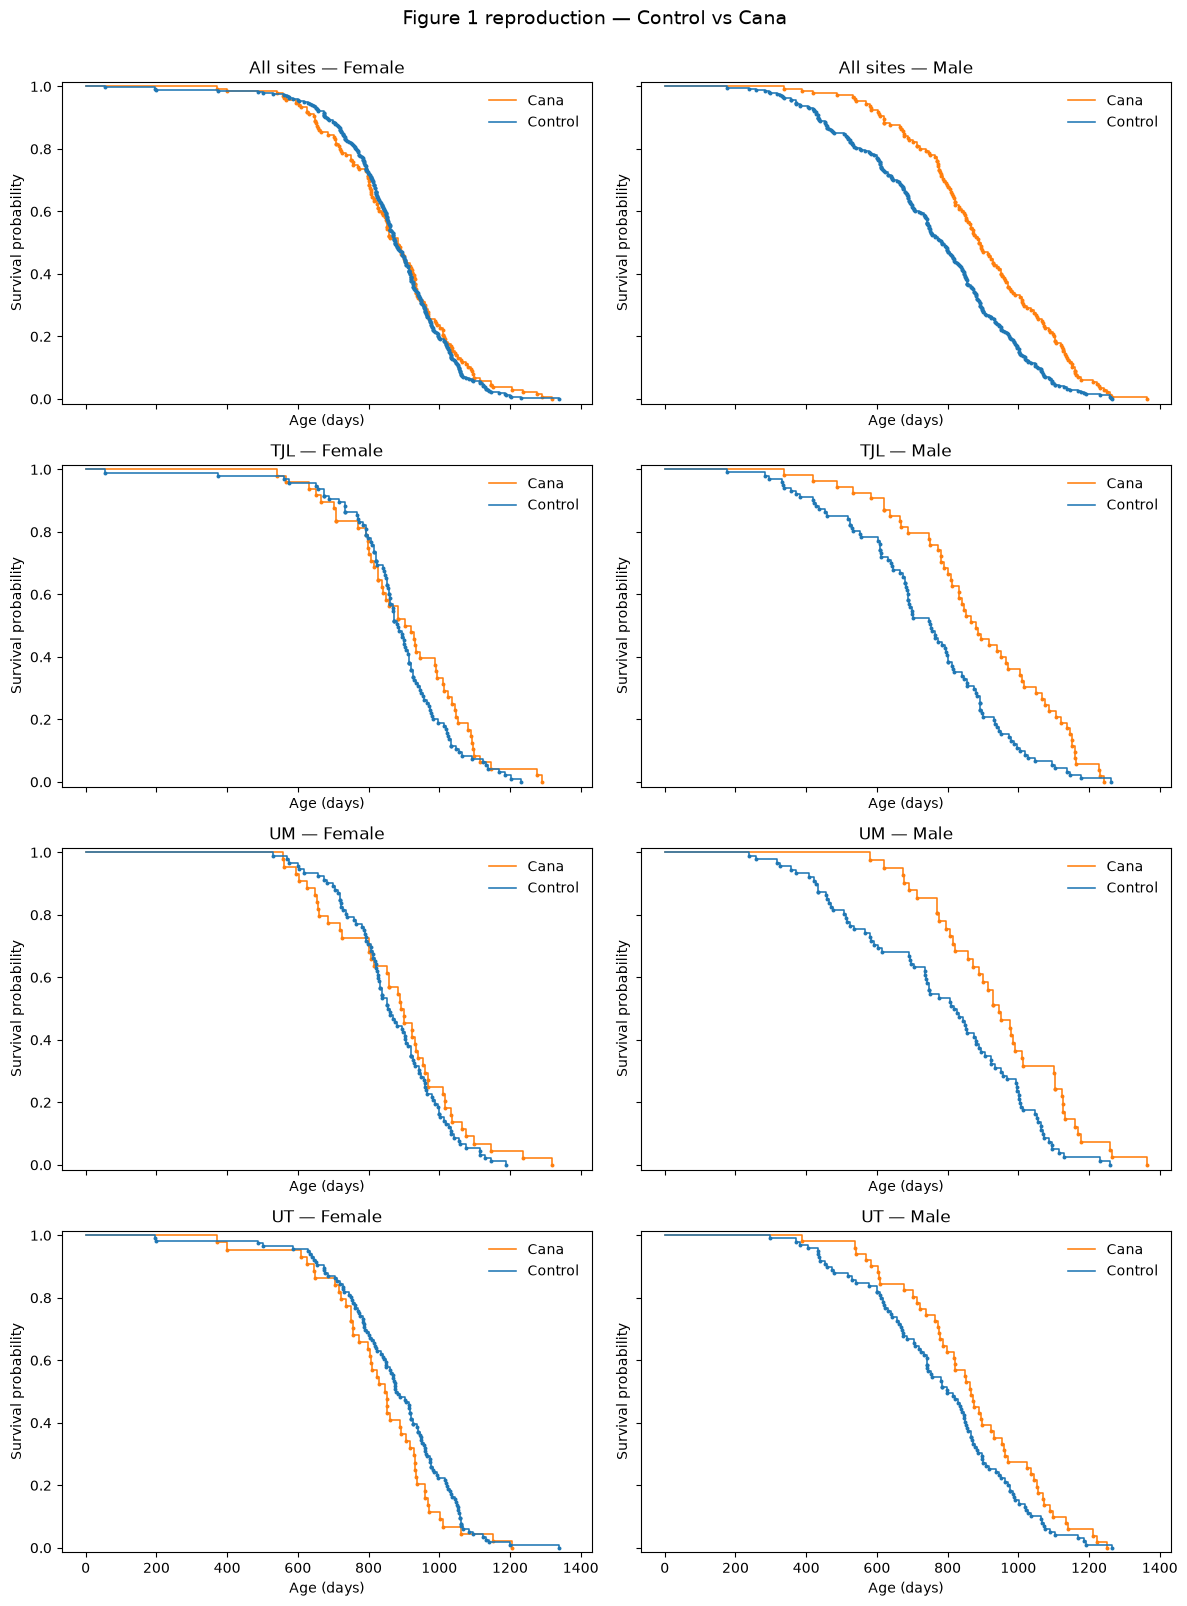

In [6]:
def draw_km_group(data, group, ax):
    """Kaplan–Meier curve with a marker for each observed death."""
    mouse_rows = data[data["group"] == group]
    fit = KaplanMeierFitter().fit(
        mouse_rows["age"],
        event_observed=mouse_rows["dead"],
        label=group,
    )

    color = "tab:blue" if group == "Control" else "tab:orange"
    z = 4 if group == "Control" else 2

    curve = fit.survival_function_.iloc[:, 0]
    ax.step(
        curve.index.to_numpy(), curve.to_numpy(),
        where="post", label=group, color=color,
        linewidth=1.15, zorder=z,
    )

    ages = mouse_rows.loc[mouse_rows["dead"].eq(1), "age"]
    heights = fit.survival_function_at_times(ages).to_numpy()
    ax.scatter(
        ages, heights, s=8, marker="o", color=color,
        zorder=z + 0.4, linewidths=0,
    )
    return fit


def draw_km_panel(data, ax, title):
    draw_km_group(data, "Cana", ax)
    draw_km_group(data, "Control", ax)
    ax.set(title=title, xlabel="Age (days)", ylabel="Survival probability")
    ax.set_ylim(-0.015, 1.015)
    ax.legend(frameon=False)


fig, axes = plt.subplots(4, 2, figsize=(12, 16), sharex=True, sharey=True)

for col, sex in enumerate(SEXES):
    sex_label = "Female" if sex == "f" else "Male"
    draw_km_panel(
        survival[survival["sex"] == sex],
        axes[0, col], f"All sites — {sex_label}",
    )
    for row, site in enumerate(SITES, start=1):
        subset = survival[
            (survival["sex"] == sex) & (survival["site"] == site)
        ]
        draw_km_panel(subset, axes[row, col], f"{site} — {sex_label}")

fig.suptitle("Figure 1 reproduction — Control vs Cana", y=1.001, fontsize=14)
plt.tight_layout()
plt.show()

## 3. Table 1 — lifespan and log-rank

Median and 90th-percentile ages use **observed deaths only**, excluding technical removals. Kaplan–Meier and log-rank analyses retain censored records. Pooled log-rank tests are **stratified by site**; site-specific tests are unstratified. Published percentile conventions may differ from NumPy interpolation.


In [7]:
def death_age_quantiles(data):
    ages = data.loc[data["dead"].eq(1), "age"].to_numpy()
    return float(np.median(ages)), float(np.percentile(ages, 90))


def logrank_p(data, pooled):
    statistic, p_value = survdiff(
        time=data["age"],
        status=data["dead"],
        group=data["group"],
        strata=data["site"] if pooled else None,
    )
    return float(statistic), float(p_value)


lifespan_rows = []
for sex in ("m", "f"):
    subset_sex = survival[survival["sex"] == sex]
    for site in ("Pool", *SITES):
        subset = (
            subset_sex if site == "Pool"
            else subset_sex[subset_sex["site"] == site]
        )
        control = subset[subset["group"] == "Control"]
        cana = subset[subset["group"] == "Cana"]

        median_c, p90_c = death_age_quantiles(control)
        median_t, p90_t = death_age_quantiles(cana)
        chi2, p = logrank_p(subset, pooled=(site == "Pool"))

        lifespan_rows.append({
            "sex": sex, "site": site,
            "n_control": len(control), "n_cana": len(cana),
            "median_control": median_c, "median_cana": median_t,
            "median_change_pct": 100 * (median_t / median_c - 1),
            "p90_control": p90_c, "p90_cana": p90_t,
            "p90_change_pct": 100 * (p90_t / p90_c - 1),
            "logrank_chi2": chi2, "logrank_p": p,
        })

lifespan_table = pd.DataFrame(lifespan_rows)
lifespan_table.round(3)

,sex,site,n_control,n_cana,median_control,median_cana,median_change_pct,p90_control,p90_cana,p90_change_pct,logrank_chi2,logrank_p
0,m,Pool,303,156,782.0,888.0,13.555,1053.8,1156.6,9.755,25.083,0.000
1,m,TJL,102,54,749.0,880.0,17.490,1002.0,1157.8,15.549,12.181,0.000
2,m,UM,102,51,814.0,946.0,16.216,1070.4,1170.0,9.305,11.425,0.001
3,m,UT,99,51,799.0,866.0,8.385,1040.8,1099.0,5.592,3.527,0.060
4,f,Pool,304,136,875.0,883.0,0.914,1055.0,1085.0,2.844,0.430,0.512
5,f,TJL,96,48,883.0,911.5,3.228,1053.0,1095.6,4.046,1.856,0.173
6,f,UM,92,44,858.0,896.5,4.487,1033.8,1072.4,3.734,1.253,0.263
7,f,UT,116,44,881.5,849.0,-3.687,1058.0,993.1,-6.134,2.159,0.142


## 4. Wang–Allison test

For each `sex × site`, the **pooled Control + Cana** Kaplan–Meier curve determines the age at which survival reaches 10%. At that cutoff, compare mice surviving to the age against observed earlier deaths via Fisher's exact test; earlier censorings are excluded. Pooled results sum site-specific counts.


In [8]:
def wang_allison_counts(data):
    # One KM curve from the two treatments COMBINED establishes the threshold.
    combined = KaplanMeierFitter().fit(data["age"], data["dead"])
    curve = combined.survival_function_.iloc[:, 0]

    cutoff = float(curve.index[curve.to_numpy() <= 0.10][0])

    rows = []
    for group in GROUPS:
        mice = data[data["group"] == group]

        alive = int(mice["age"].ge(cutoff).sum())
        died_earlier = int(
            (mice["age"].lt(cutoff) & mice["dead"].eq(1)).sum()
        )
        # Early censorings are deliberately absent from either count.
        rows.append({
            "group": group, "threshold_age": cutoff,
            "alive": alive, "dead": died_earlier,
        })
    return pd.DataFrame(rows)


wa_counts = pd.concat(
    [
        wang_allison_counts(
            survival[
                (survival["sex"] == sex)
                & (survival["site"] == site)
            ]
        ).assign(sex=sex, site=site)
        for sex in ("m", "f")
        for site in SITES
    ],
    ignore_index=True,
)
wa_counts

,group,threshold_age,alive,dead,sex,site
0,Control,1122.0,4,90,m,TJL
1,Cana,1122.0,11,42,m,TJL
2,Control,1123.0,3,79,m,UM
3,Cana,1123.0,10,31,m,UM
4,Control,1073.0,8,91,m,UT
5,Cana,1073.0,7,44,m,UT
6,Control,1092.0,8,87,f,TJL
7,Cana,1092.0,7,41,f,TJL
8,Control,1055.0,8,84,f,UM
9,Cana,1055.0,6,38,f,UM


In [9]:
wa_rows = []
for sex in ("m", "f"):
    sex_counts = wa_counts[wa_counts["sex"] == sex]
    for site in ("Pool", *SITES):
        counts = (
            sex_counts if site == "Pool"
            else sex_counts[sex_counts["site"] == site]
        )
        contingency = (
            counts.groupby("group")[["alive", "dead"]]
            .sum()
            .reindex(GROUPS)
        )
        odds_ratio, p_value = fisher_exact(
            contingency.to_numpy(), alternative="two-sided"
        )
        wa_rows.append({
            "sex": sex, "site": site,
            "wa_odds_control_over_cana": odds_ratio,
            "wa_p": p_value,
            "control_alive": int(contingency.loc["Control", "alive"]),
            "cana_alive": int(contingency.loc["Cana", "alive"]),
        })

wa_table = pd.DataFrame(wa_rows)
wa_table.round(5)

,sex,site,wa_odds_control_over_cana,wa_p,control_alive,cana_alive
0,m,Pool,0.24107,0.00003,15,28
1,m,TJL,0.16970,0.00309,4,11
2,m,UM,0.11772,0.00090,3,10
3,m,UT,0.55259,0.38869,8,7
4,f,Pool,0.79380,0.49852,29,16
5,f,TJL,0.53859,0.26253,8,7
6,f,UM,0.60317,0.38023,8,6
7,f,UT,1.72492,0.55976,13,3


## 5. Table 1 — calculated vs published

Published values are separate reference columns. Differences remain visible. Published male pooled P values of `<0.0001` are stored as `0.0001` thresholds, not exact values.


In [10]:
published_table1 = pd.DataFrame([
    # sex site n_control n_cana median_control median_cana p90_control p90_cana
    ("m", "Pool",303,156,787,897,1047,1143,14,9, 0.0001,0.0001),
    ("m", "TJL", 102, 54,749,880,1005,1159,17,15,0.001,0.003),
    ("m", "UM",  102, 51,814,946,1071,1170,16,9, 0.001,0.001),
    ("m", "UT",   99, 51,799,866,1064,1099,8, 3,  0.060,0.39),
    ("f", "Pool",304,136,874,886,1050,1059,1, 1,  0.512,0.50),
    ("f", "TJL",  96, 48,883,912,1057,1097,3, 4,  0.173,0.26),
    ("f", "UM",   92, 44,858,897,1034,1076,4, 4,  0.263,0.38),
    ("f", "UT",  116, 44,882,849,1058,1003,-4,-5, 0.142,0.56),
], columns=[
    "sex", "site", "n_control_pub", "n_cana_pub",
    "median_control_pub", "median_cana_pub",
    "p90_control_pub", "p90_cana_pub",
    "median_change_pct_pub", "p90_change_pct_pub",
    "logrank_p_pub", "wa_p_pub",
])

calculated_table1 = lifespan_table.merge(
    wa_table[["sex", "site", "wa_p"]], on=["sex", "site"]
)
comparison = calculated_table1.merge(
    published_table1, on=["sex", "site"], validate="one_to_one"
)

for name in ("n_control", "n_cana", "median_control", "median_cana",
             "p90_control", "p90_cana", "median_change_pct", "p90_change_pct"):
    comparison[name + "_difference"] = (
        comparison[name] - comparison[name + "_pub"]
    )

comparison[[
    "sex", "site", "n_control", "n_cana",
    "median_control", "median_control_pub", "median_cana", "median_cana_pub",
    "p90_control", "p90_control_pub", "p90_cana", "p90_cana_pub",
    "logrank_p", "logrank_p_pub", "wa_p", "wa_p_pub",
]].round(4)

,sex,site,n_control,n_cana,median_control,median_control_pub,median_cana,median_cana_pub,p90_control,p90_control_pub,p90_cana,p90_cana_pub,logrank_p,logrank_p_pub,wa_p,wa_p_pub
0,m,Pool,303,156,782.0,787,888.0,897,1053.8,1047,1156.6,1143,0.0000,0.0001,0.0000,0.0001
1,m,TJL,102,54,749.0,749,880.0,880,1002.0,1005,1157.8,1159,0.0005,0.0010,0.0031,0.0030
2,m,UM,102,51,814.0,814,946.0,946,1070.4,1071,1170.0,1170,0.0007,0.0010,0.0009,0.0010
3,m,UT,99,51,799.0,799,866.0,866,1040.8,1064,1099.0,1099,0.0604,0.0600,0.3887,0.3900
4,f,Pool,304,136,875.0,874,883.0,886,1055.0,1050,1085.0,1059,0.5120,0.5120,0.4985,0.5000
5,f,TJL,96,48,883.0,883,911.5,912,1053.0,1057,1095.6,1097,0.1730,0.1730,0.2625,0.2600
6,f,UM,92,44,858.0,858,896.5,897,1033.8,1034,1072.4,1076,0.2630,0.2630,0.3802,0.3800
7,f,UT,116,44,881.5,882,849.0,849,1058.0,1058,993.1,1003,0.1418,0.1420,0.5598,0.5600


## 6. Figure 2 — drug concentrations (published only)

Plasma Cana at 22 months, mean ± SEM: **female 13.2 ± 0.9 μg/mL (n=5)**; **male 3.6 ± 0.6 μg/mL (n=8)**. Female exposure was higher despite no lifespan benefit. Individual plasma/brain/kidney measurements are unavailable; plots cannot be reconstructed. [Paper](https://insight.jci.org/articles/view/140019).


## 7. Figure 3 — body weight

Weights at 6, 12, 18 and 24 months; treatment starts at month 7. Mean ± SEM of measured, living mice at each age:

$$
\mathrm{SEM}=\frac{s}{\sqrt{n}}
$$

Two-sided equal-variance Student t-tests compare Control and Cana separately for each sex and age, pooling sites.


In [11]:
weights_raw = pd.read_excel(WEIGHT_FILE, sheet_name="Data")
weights = weights_raw.loc[
    weights_raw["group"].isin(GROUPS),
    ["site", "sex", "animal_id", "group", "age_months", "body_weight_g"],
].copy()

weight_summary = (
    weights.groupby(["sex", "group", "age_months"])
    .agg(
        n=("body_weight_g", "count"),
        mean_g=("body_weight_g", "mean"),
        sem_g=("body_weight_g", "sem"),
    )
    .reset_index()
)
weight_summary.round(2)

,sex,group,age_months,n,mean_g,sem_g
0,f,Cana,6,136,34.04,0.60
1,f,Cana,12,136,34.10,0.52
2,f,Cana,18,133,36.98,0.61
3,f,Cana,24,107,37.14,0.65
4,f,Control,6,303,33.83,0.37
5,f,Control,12,301,41.19,0.47
6,f,Control,18,297,45.52,0.55
7,f,Control,24,255,44.65,0.61
8,m,Cana,6,151,41.81,0.45
9,m,Cana,12,141,43.69,0.52


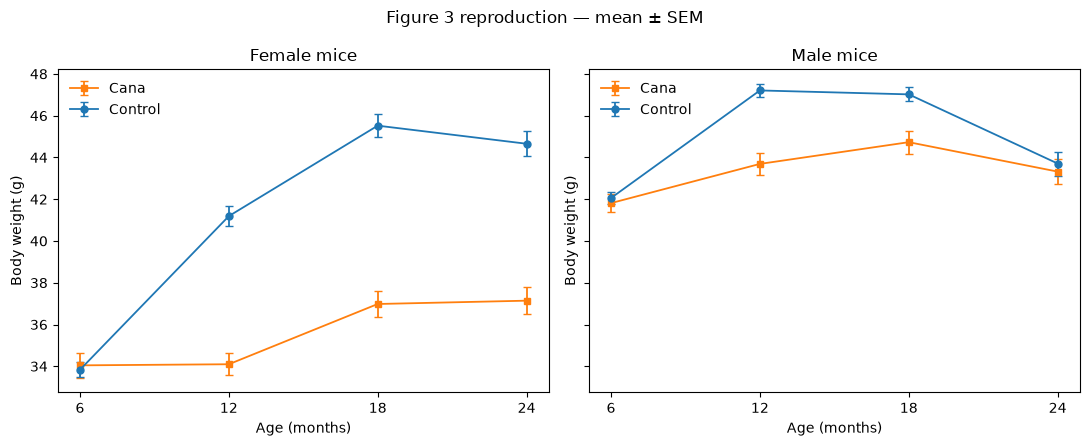

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

for ax, sex in zip(axes, SEXES):
    for group, color, marker in [
        ("Cana", "tab:orange", "s"),
        ("Control", "tab:blue", "o"),
    ]:
        x = weight_summary[
            (weight_summary["sex"] == sex)
            & (weight_summary["group"] == group)
        ].sort_values("age_months")
        ax.errorbar(
            x["age_months"], x["mean_g"], yerr=x["sem_g"],
            label=group, color=color, marker=marker,
            linewidth=1.3, markersize=5, capsize=3,
        )
    ax.set(
        title="Female mice" if sex == "f" else "Male mice",
        xlabel="Age (months)", ylabel="Body weight (g)",
        xticks=[6, 12, 18, 24],
    )
    ax.legend(frameon=False)

fig.suptitle("Figure 3 reproduction — mean ± SEM")
plt.tight_layout()
plt.show()

### Figure 3 — tests

Student's two-sided t-test (`equal_var=True`) at each sex × age. Published significant differences: females at 12, 18, 24 months; males at 12, 18 months.


In [13]:
weight_rows = []
for (sex, age), group_data in weights.groupby(["sex", "age_months"]):
    c = group_data.loc[
        group_data["group"] == "Control", "body_weight_g"
    ].dropna()
    t = group_data.loc[
        group_data["group"] == "Cana", "body_weight_g"
    ].dropna()

    test = ttest_ind(c, t, equal_var=True, alternative="two-sided")
    weight_rows.append({
        "sex": sex, "age_months": age,
        "n_control": len(c), "n_cana": len(t),
        "control_mean_g": c.mean(), "cana_mean_g": t.mean(),
        "change_pct": (t.mean() / c.mean() - 1) * 100,
        "t_statistic": float(test.statistic),
        "p_value": float(test.pvalue),
    })

weight_tests = pd.DataFrame(weight_rows)
weight_tests.round(5)

,sex,age_months,n_control,n_cana,control_mean_g,cana_mean_g,change_pct,t_statistic,p_value
0,f,6,303,136,33.83267,34.04412,0.62497,-0.31242,0.75487
1,f,12,301,136,41.18937,34.09706,-17.21879,9.00916,0.00000
2,f,18,297,133,45.52088,36.98195,-18.75825,9.35739,0.00000
3,f,24,255,107,44.65490,37.14112,-16.82633,7.27512,0.00000
4,m,6,286,151,42.05594,41.81258,-0.57866,0.46804,0.63999
5,m,12,268,141,47.20713,43.68936,-7.45177,6.17859,0.00000
6,m,18,220,137,47.01955,44.72993,-4.86950,3.77165,0.00019
7,m,24,162,116,43.70741,43.32069,-0.88479,0.46103,0.64514


## 8. HbA1c (published only)

Two-way ANOVA (sex × treatment): no treatment effect, significant sex effect. Means: male Control **3.8%**, Cana **3.7%**; female Control **3.5%**, Cana **3.5%**. Individual observations unavailable.


## 9. Figure 4 — metabolic outcomes (published only)

Separate 20–22-month subcohort: NMR body composition, fasting glucose and glucose tolerance. Reported in females: **~18% lower body mass**, **41% lower fat mass**; glucose tolerance improved in both sexes. Individual measurements unavailable.


## 10. Table 2 — pathology

Blinded pathology of **120 mice** (60 Control, 60 Cana). Published cause-of-death counts support category-wise Fisher exact tests; individual pathology records are unavailable.


In [14]:
pathology = pd.DataFrame({
    "cause": [
        "Hematopoietic neoplasia",
        "Hemangiosarcoma",
        "Liver neoplasia",
        "Lung carcinoma",
        "Neoplastic, other",
        "Atrial thrombosis",
        "Non-neoplastic, other",
        "Multiple or unknown",
        "Autolysis",
    ],
    "Cana": [18, 2, 3, 2, 9, 5, 6, 10, 5],
    "Control": [16, 3, 4, 5, 8, 2, 6, 11, 5],
})
pathology["Total"] = pathology["Control"] + pathology["Cana"]
pathology

,cause,Cana,Control,Total
0,Hematopoietic neoplasia,18,16,34
1,Hemangiosarcoma,2,3,5
2,Liver neoplasia,3,4,7
3,Lung carcinoma,2,5,7
4,"Neoplastic, other",9,8,17
5,Atrial thrombosis,5,2,7
6,"Non-neoplastic, other",6,6,12
7,Multiple or unknown,10,11,21
8,Autolysis,5,5,10


In [15]:
pathology_rows = []
for row in pathology.itertuples(index=False):
    table = np.array([
        [row.Control, 60 - row.Control],
        [row.Cana, 60 - row.Cana],
    ])
    odds_ratio, p_value = fisher_exact(table, alternative="two-sided")
    pathology_rows.append({
        "cause": row.cause, "Control": row.Control,
        "Cana": row.Cana, "odds_ratio": odds_ratio,
        "fisher_p": p_value,
    })

pathology_tests = pd.DataFrame(pathology_rows)
pathology_tests.round(4)

,cause,Control,Cana,odds_ratio,fisher_p
0,Hematopoietic neoplasia,16,18,0.8485,0.8397
1,Hemangiosarcoma,3,2,1.5263,1.0000
2,Liver neoplasia,4,3,1.3571,1.0000
3,Lung carcinoma,5,2,2.6364,0.4390
4,"Neoplastic, other",8,9,0.8718,1.0000
5,Atrial thrombosis,2,5,0.3793,0.4390
6,"Non-neoplastic, other",6,6,1.0000,1.0000
7,Multiple or unknown,11,10,1.1224,1.0000
8,Autolysis,5,5,1.0000,1.0000


### Pathology results

Hematopoietic neoplasia: **16/60 Control**, **18/60 Cana**. No significant differences by individual cause-of-death category. Neoplastic deaths among evaluable mice: **36/44 Control**, **34/45 Cana** (excludes ambiguous/autolyzed cases).


## 11. Supplemental pathology (published only)

**21 binary lesions:** Fisher exact tests. **14 graded lesions:** two-sided Student t-tests. Mild liver telangiectasia/angiectasis: mean **0.41 Cana vs 0.09 Control; P = 0.01**. Mouse-level lesion records unavailable. [Supplement](https://doi.org/10.1172/jci.insight.140019DS1).


In [19]:
from lifelines import CoxPHFitter

male = survival.loc[
    survival["sex"] == "m",
    ["age", "dead", "group", "site"]
].copy()

male["cana"] = (male["group"] == "Cana").astype(int)

In [23]:
male.head()

,age,dead,group,site,cana
363,666,1,Cana,TJL,1
364,669,1,Cana,TJL,1
365,966,1,Cana,TJL,1
366,1139,1,Cana,TJL,1
367,1122,1,Cana,TJL,1


In [25]:
cph = CoxPHFitter()
cph.fit(male, 'age', 'dead', strata=['site'], formula='cana')
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 459 total observations, 39 right-censored observations>
             duration col = 'age'
                event col = 'dead'
                   strata = site
      baseline estimation = breslow
   number of observations = 459
number of events observed = 420
   partial log-likelihood = -1657.75
         time fit was run = 2026-10-22 09:44:11 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
cana      -0.53      0.59      0.11           -0.73           -0.32                0.48                0.73

           cmp to     z      p  -log2(p)
covariate                               
cana         0.00 -4.96 <0.005     20.41
---
Concordance = 0.57
Partial AIC = 3317.51
log-likelihood ratio test = 25.67 on 1 df
-log2(p) of ll-ratio test = 21.24

In [26]:
female = survival.loc[
    survival["sex"] == "f",
    ["age", "dead", "group", "site"],
].copy()

female["cana"] = (female["group"] == "Cana").astype(int)

cph_f = CoxPHFitter()

cph_f.fit(
    female,
    duration_col="age",
    event_col="dead",
    strata=["site"],
    formula="cana",
)

cph_f.summary[[
    "exp(coef)",
    "exp(coef) lower 95%",
    "exp(coef) upper 95%",
    "p",
]]

,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,
cana,0.932059,0.756477,1.148396,0.508815


In [28]:
from lifelines import CoxPHFitter

cox_data = survival[
    ["age", "dead", "group", "sex", "site"]
].copy()

cox_data["cana"] = (cox_data["group"] == "Cana").astype(int)
cox_data["male"] = (cox_data["sex"] == "m").astype(int)

cox_data["cana_x_male"] = (
    cox_data["cana"] * cox_data["male"]
)

cph_interaction = CoxPHFitter()

cph_interaction.fit(
    cox_data,
    duration_col="age",
    event_col="dead",
    strata=["site", "sex"],
    formula="cana + cana_x_male",
)

cph_interaction.summary[[
    "coef",
    "exp(coef)",
    "exp(coef) lower 95%",
    "exp(coef) upper 95%",
    "p",
]]

,coef,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,,
cana,-0.070359,0.932059,0.756477,1.148396,0.508815
cana_x_male,-0.455353,0.634224,0.472399,0.851485,0.002448



   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'cana_x_male' failed the non-proportional test: p-value is 0.0120.

   Advice: with so few unique values (only 2), you can include `strata=['cana_x_male', ...]` in the
call in `.fit`. See documentation in link [E] below.

---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-on-it
[C]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Introduce-time-varying-covariates
[D]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Modify-the-functional-form
[E]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Stratification



[[<Axes: xlabel='rank-transformed time\n(p=0.1363)'>,
  <Axes: xlabel='km-transformed time\n(p=0.1022)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.9602)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0120)'>]]

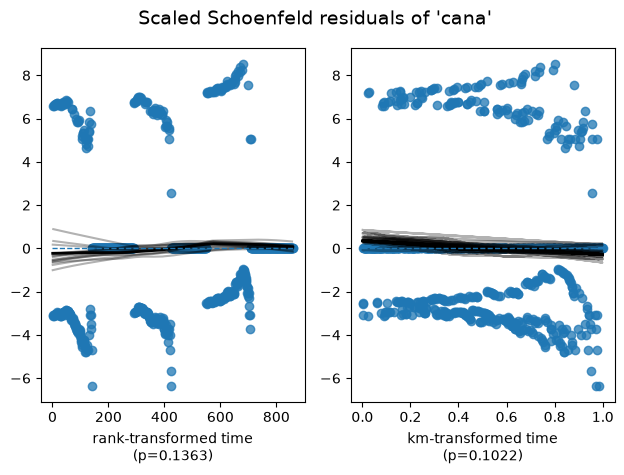

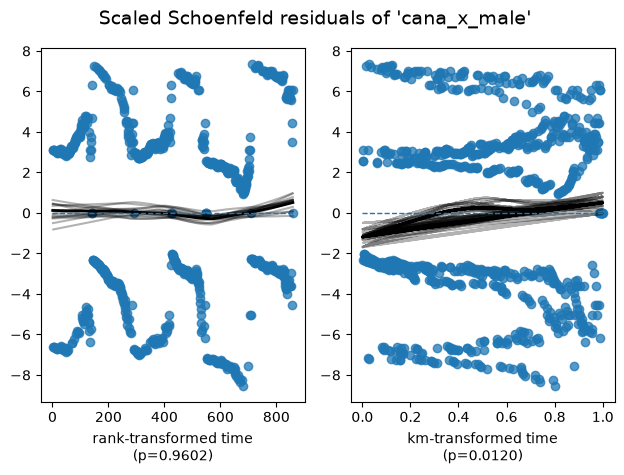

In [29]:
cph_interaction.check_assumptions(
    cox_data,
    p_value_threshold=0.05,
    show_plots=True,
)

In [30]:
from lifelines import CoxPHFitter
import pandas as pd

intervals = [
    (0, 700),
    (700, 900),
    (900, float("inf")),
]

rows = []

for sex in ["m", "f"]:
    data = survival[survival["sex"] == sex].copy()
    data["cana"] = (data["group"] == "Cana").astype(int)

    for start, end in intervals:
        x = data[data["age"] > start].copy()

        x["duration"] = x["age"].clip(upper=end) - start
        x["event"] = (
            (x["dead"] == 1)
            & (x["age"] <= end)
        ).astype(int)

        model = CoxPHFitter()
        model.fit(
            x[["duration", "event", "site", "cana"]],
            duration_col="duration",
            event_col="event",
            strata=["site"],
        )

        result = model.summary.loc["cana"]

        rows.append({
            "sex": sex,
            "age_interval": f"{start}–{end}",
            "deaths": x["event"].sum(),
            "HR": result["exp(coef)"],
            "CI_lower": result["exp(coef) lower 95%"],
            "CI_upper": result["exp(coef) upper 95%"],
            "p": result["p"],
        })

age_effects = pd.DataFrame(rows)
age_effects.round(3)

,sex,age_interval,deaths,HR,CI_lower,CI_upper,p
0,m,0–700,133,0.378,0.245,0.585,0.000
1,m,700–900,144,0.720,0.512,1.013,0.059
2,m,900–inf,143,0.669,0.474,0.944,0.022
3,f,0–700,55,1.440,0.835,2.484,0.189
4,f,700–900,184,0.940,0.682,1.295,0.705
5,f,900–inf,200,0.807,0.587,1.110,0.187


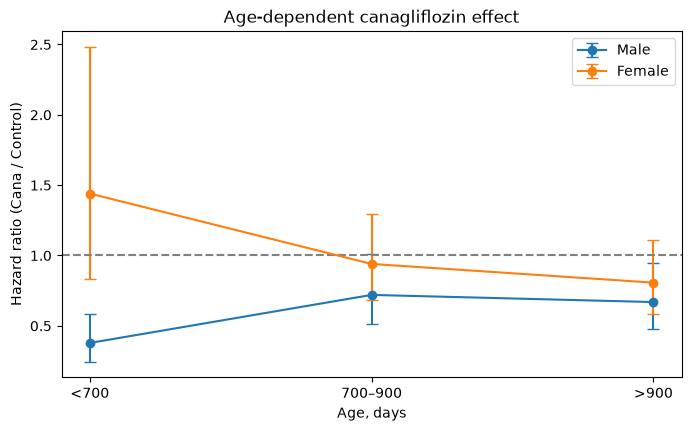

In [31]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))

for sex, label in [("m", "Male"), ("f", "Female")]:
    x = age_effects[age_effects["sex"] == sex]

    ax.errorbar(
        range(len(x)),
        x["HR"],
        yerr=[
            x["HR"] - x["CI_lower"],
            x["CI_upper"] - x["HR"],
        ],
        fmt="o-",
        capsize=4,
        label=label,
    )

ax.axhline(1, color="gray", linestyle="--")

ax.set(
    xticks=range(3),
    xticklabels=["<700", "700–900", ">900"],
    xlabel="Age, days",
    ylabel="Hazard ratio (Cana / Control)",
    title="Age-dependent canagliflozin effect",
)

ax.legend()
plt.show()

In [32]:
from lifelines import CoxTimeVaryingFitter
from scipy.stats import chi2
import pandas as pd
import numpy as np

data = survival[
    ["age", "dead", "group", "sex", "site"]
].copy()

data["id"] = np.arange(len(data))
data["cana"] = (data["group"] == "Cana").astype(int)
data["male"] = (data["sex"] == "m").astype(int)

rows = []

for r in data.itertuples():
    for start, end in [(0, 700), (700, 900), (900, np.inf)]:
        if r.age <= start:
            continue

        stop = min(r.age, end)

        rows.append({
            "id": r.id,
            "site": r.site,
            "sex": r.sex,
            "start": start,
            "stop": stop,
            "event": int(r.dead == 1 and r.age == stop),
            "cana": r.cana,
            "male": r.male,
            "period": 0 if start == 0 else 1 if start == 700 else 2,
        })

tv = pd.DataFrame(rows)

In [33]:
tv["mid"] = (tv["period"] == 1).astype(int)
tv["late"] = (tv["period"] == 2).astype(int)

tv["cana_mid"] = tv["cana"] * tv["mid"]
tv["cana_late"] = tv["cana"] * tv["late"]

tv["cana_male"] = tv["cana"] * tv["male"]

tv["cana_male_mid"] = tv["cana_male"] * tv["mid"]
tv["cana_male_late"] = tv["cana_male"] * tv["late"]

In [34]:
base_cols = [
    "cana",
    "cana_mid",
    "cana_late",
    "cana_male",
]

full_cols = base_cols + [
    "cana_male_mid",
    "cana_male_late",
]

def fit_tv(columns):
    model = CoxTimeVaryingFitter()

    model.fit(
        tv[
            ["id", "site", "sex", "start", "stop", "event"]
            + columns
        ],
        id_col="id",
        start_col="start",
        stop_col="stop",
        event_col="event",
        strata=["site", "sex"],
    )

    return model


base_model = fit_tv(base_cols)
full_model = fit_tv(full_cols)

In [35]:
lr_stat = 2 * (
    full_model.log_likelihood_
    - base_model.log_likelihood_
)

p_value = chi2.sf(lr_stat, df=2)

print("LR statistic:", lr_stat)
print("p-value:", p_value)

LR statistic: 7.914987951947296
p-value: 0.019110946823747917


In [36]:
full_model.summary[[
    "coef",
    "exp(coef)",
    "exp(coef) lower 95%",
    "exp(coef) upper 95%",
    "p",
]]

,coef,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,,
cana,0.364853,1.440303,0.835142,2.483975,0.189489
cana_mid,-0.426809,0.652588,0.346785,1.228056,0.185796
cana_late,-0.579170,0.560363,0.298109,1.053329,0.072079
cana_male,-1.337153,0.262592,0.130700,0.527580,0.000172
cana_male_mid,1.070407,2.916566,1.258863,6.757178,0.012526
cana_male_late,1.149452,3.156464,1.361863,7.315908,0.007360


In [37]:
from lifelines import KaplanMeierFitter
from lifelines.utils import restricted_mean_survival_time
import pandas as pd
import numpy as np

tau = 1000

def rmst(data):
    km = KaplanMeierFitter().fit(
        data["age"],
        event_observed=data["dead"],
    )
    return restricted_mean_survival_time(km, t=tau)


rows = []

for sex in ["m", "f"]:
    data = survival[survival["sex"] == sex]

    control = data[data["group"] == "Control"]
    cana = data[data["group"] == "Cana"]

    control_rmst = rmst(control)
    cana_rmst = rmst(cana)

    rows.append({
        "sex": sex,
        "Control": control_rmst,
        "Cana": cana_rmst,
        "difference_days": cana_rmst - control_rmst,
    })

rmst_results = pd.DataFrame(rows)
rmst_results.round(2)

,sex,Control,Cana,difference_days
0,m,751.66,856.28,104.62
1,f,857.85,851.26,-6.60


In [39]:
rng = np.random.default_rng(42)
n_boot = 2000

boot_results = []

for sex in ["m", "f"]:
    data = survival[survival["sex"] == sex]
    strata = list(data.groupby(["site", "group"]))

    differences = []

    for _ in range(n_boot):
        sample = pd.concat([
            group.iloc[rng.integers(0, len(group), len(group))]
            for _, group in strata
        ])

        control = sample[sample["group"] == "Control"]
        cana = sample[sample["group"] == "Cana"]

        differences.append(rmst(cana) - rmst(control))

    lower, upper = np.percentile(differences, [2.5, 97.5])

    boot_results.append({
        "sex": sex,
        "CI_lower": lower,
        "CI_upper": upper,
    })

rmst_results = rmst_results.merge(
    pd.DataFrame(boot_results),
    on="sex",
)

rmst_results.round(2)

,sex,Control,Cana,difference_days,CI_lower_x,CI_upper_x,CI_lower_y,CI_upper_y
0,m,751.66,856.28,104.62,70.76,138.17,70.76,138.17
1,f,857.85,851.26,-6.60,-34.85,21.47,-34.85,21.47


In [42]:
import numpy as np
import pandas as pd

tau = 1000
rng = np.random.default_rng(42)
n_boot = 2000

def fast_rmst(age, dead):
    order = np.argsort(age)
    t = age[order]
    d = dead[order]

    death_times, counts = np.unique(t[d == 1], return_counts=True)
    death_times = death_times[death_times <= tau]
    counts = counts[:len(death_times)]

    at_risk = len(t) - np.searchsorted(t, death_times)
    survival_prob = np.cumprod(1 - counts / at_risk)

    times = np.r_[0, death_times, tau]
    survival_values = np.r_[1, survival_prob]

    return np.sum(np.diff(times) * survival_values)


results = []

for sex, data in survival.groupby("sex"):
    strata = [
        (group["age"].to_numpy(), group["dead"].to_numpy(), name[1])
        for name, group in data.groupby(["site", "group"])
    ]

    differences = np.empty(n_boot)

    for i in range(n_boot):
        samples = {"Control": [], "Cana": []}

        for ages, deaths, group in strata:
            idx = rng.integers(len(ages), size=len(ages))
            samples[group].append((ages[idx], deaths[idx]))

        values = {}

        for group, parts in samples.items():
            ages = np.concatenate([x[0] for x in parts])
            deaths = np.concatenate([x[1] for x in parts])
            values[group] = fast_rmst(ages, deaths)

        differences[i] = values["Cana"] - values["Control"]

    results.append({
        "sex": sex,
        "CI_lower": np.percentile(differences, 2.5),
        "CI_upper": np.percentile(differences, 97.5),
    })

display(rmst_results.drop(
    columns=["CI_lower", "CI_upper"],
    errors="ignore",
).merge(pd.DataFrame(results), on="sex").round(2))

,sex,Control,Cana,difference_days,CI_lower_x,CI_upper_x,CI_lower_y,CI_upper_y,CI_lower,CI_upper
0,m,751.66,856.28,104.62,70.76,138.17,70.76,138.17,70.78,139.18
1,f,857.85,851.26,-6.60,-34.85,21.47,-34.85,21.47,-34.07,20.79


In [43]:
rmst_results = rmst_results[
    ["sex", "Control", "Cana", "difference_days"]
].merge(pd.DataFrame(results), on="sex")

display(rmst_results.round(2))

,sex,Control,Cana,difference_days,CI_lower,CI_upper
0,m,751.66,856.28,104.62,70.78,139.18
1,f,857.85,851.26,-6.60,-34.07,20.79


In [44]:
rng = np.random.default_rng(42)
n_boot = 2000

strata = {
    sex: {
        group: [
            (part["age"].to_numpy(), part["dead"].to_numpy())
            for _, part in sex_data[
                sex_data["group"] == group
            ].groupby("site")
        ]
        for group in ["Control", "Cana"]
    }
    for sex, sex_data in survival.groupby("sex")
}

def bootstrap_rmst(parts):
    ages = []
    deaths = []

    for age, dead in parts:
        idx = rng.integers(len(age), size=len(age))
        ages.append(age[idx])
        deaths.append(dead[idx])

    return fast_rmst(
        np.concatenate(ages),
        np.concatenate(deaths),
    )

interaction_samples = np.empty(n_boot)

for i in range(n_boot):
    male_effect = (
        bootstrap_rmst(strata["m"]["Cana"])
        - bootstrap_rmst(strata["m"]["Control"])
    )

    female_effect = (
        bootstrap_rmst(strata["f"]["Cana"])
        - bootstrap_rmst(strata["f"]["Control"])
    )

    interaction_samples[i] = male_effect - female_effect

point_estimate = (
    rmst_results.loc[rmst_results["sex"] == "m", "difference_days"].iloc[0]
    - rmst_results.loc[rmst_results["sex"] == "f", "difference_days"].iloc[0]
)

ci = np.percentile(interaction_samples, [2.5, 97.5])

print(f"RMST interaction: {point_estimate:.2f} days")
print(f"95% bootstrap CI: [{ci[0]:.2f}, {ci[1]:.2f}]")

RMST interaction: 111.21 days
95% bootstrap CI: [67.99, 156.63]


In [45]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n_boot = 2000

def survival_quantiles(age, dead):
    death_times = np.unique(age[dead == 1])

    at_risk = len(age) - np.searchsorted(np.sort(age), death_times)
    deaths = np.searchsorted(
        np.sort(age[dead == 1]),
        death_times,
        side="right",
    ) - np.searchsorted(
        np.sort(age[dead == 1]),
        death_times,
        side="left",
    )

    s = np.cumprod(1 - deaths / at_risk)

    def quantile(threshold):
        indices = np.flatnonzero(s <= threshold)
        return death_times[indices[0]] if len(indices) else np.nan

    return np.array([quantile(0.5), quantile(0.1)])


groups = {
    (sex, group): [
        (part["age"].to_numpy(), part["dead"].to_numpy())
        for _, part in data.groupby("site")
    ]
    for (sex, group), data in survival.groupby(["sex", "group"])
}

def get_quantiles(parts, bootstrap=False):
    samples = []
    for ages, dead in parts:
        if bootstrap:
            idx = rng.integers(len(ages), size=len(ages))
            ages, dead = ages[idx], dead[idx]
        samples.append((ages, dead))

    return survival_quantiles(
        np.concatenate([a for a, _ in samples]),
        np.concatenate([d for _, d in samples]),
    )


rows = []

for sex in ["m", "f"]:
    control = get_quantiles(groups[sex, "Control"])
    cana = get_quantiles(groups[sex, "Cana"])

    differences = np.array([
        get_quantiles(groups[sex, "Cana"], bootstrap=True)
        - get_quantiles(groups[sex, "Control"], bootstrap=True)
        for _ in range(n_boot)
    ])

    for j, metric in enumerate(["median", "90th_percentile"]):
        valid = differences[:, j]
        valid = valid[np.isfinite(valid)]

        rows.append({
            "sex": sex,
            "metric": metric,
            "Control": control[j],
            "Cana": cana[j],
            "difference_days": cana[j] - control[j],
            "CI_lower": np.percentile(valid, 2.5) if len(valid) else np.nan,
            "CI_upper": np.percentile(valid, 97.5) if len(valid) else np.nan,
            "bootstrap_valid": len(valid),
        })

quantile_results = pd.DataFrame(rows)
display(quantile_results.round(2))

,sex,metric,Control,Cana,difference_days,CI_lower,CI_upper,bootstrap_valid
0,m,median,784,888,104,51.0,175.0,2000
1,m,90th_percentile,1055,1159,104,60.0,157.0,2000
2,f,median,875,883,8,-44.0,47.0,2000
3,f,90th_percentile,1055,1089,34,-17.0,87.0,2000


In [46]:
from lifelines import CoxPHFitter
from scipy.stats import chi2
import numpy as np
import pandas as pd

rows = []

for sex in ["m", "f"]:
    data = survival.loc[
        survival["sex"] == sex,
        ["age", "dead", "group", "site"]
    ].copy()

    data["cana"] = (data["group"] == "Cana").astype(int)

    sites = sorted(data["site"].unique())
    reference = sites[0]  # TJL

    interaction_cols = []

    for site in sites[1:]:
        col = f"cana_{site}"
        data[col] = data["cana"] * (data["site"] == site)
        interaction_cols.append(col)

    base = CoxPHFitter().fit(
        data,
        duration_col="age",
        event_col="dead",
        strata=["site"],
        formula="cana",
    )

    full = CoxPHFitter().fit(
        data,
        duration_col="age",
        event_col="dead",
        strata=["site"],
        formula="cana + " + " + ".join(interaction_cols),
    )

    lr = 2 * (full.log_likelihood_ - base.log_likelihood_)
    p = chi2.sf(lr, df=len(interaction_cols))

    beta = full.params_

    site_hrs = {
        reference: np.exp(beta["cana"]),
        **{
            site: np.exp(beta["cana"] + beta[f"cana_{site}"])
            for site in sites[1:]
        },
    }

    rows.append({
        "sex": sex,
        **{f"HR_{site}": hr for site, hr in site_hrs.items()},
        "LR_stat": lr,
        "p_heterogeneity": p,
    })

site_results = pd.DataFrame(rows)
display(site_results.round(4))

,sex,HR_TJL,HR_UM,HR_UT,LR_stat,p_heterogeneity
0,m,0.5432,0.5112,0.7217,2.0396,0.3607
1,f,0.7808,0.8103,1.3000,4.8121,0.0902


In [47]:
import pandas as pd

body_weight = pd.read_excel("BodyWeight_C2016.xlsx")

display(body_weight.head(8))
print(body_weight.columns.tolist())
print(body_weight.shape)

,cohort,site,sex,animal_id,group,dose_ppm,age_months,body_weight_g,source_measnums
0,C2016,TJL,m,JL12918,17aE2_16m,14.4,6,48.0,145442
1,C2016,TJL,m,JL12918,17aE2_16m,14.4,12,53.0,145445
2,C2016,TJL,m,JL12918,17aE2_16m,14.4,18,41.0,145448
3,C2016,TJL,m,JL12918,17aE2_16m,14.4,24,42.0,145451
4,C2016,TJL,m,JL12919,17aE2_16m,14.4,6,38.0,145442
5,C2016,TJL,m,JL12919,17aE2_16m,14.4,12,40.0,145445
6,C2016,TJL,m,JL12919,17aE2_16m,14.4,18,36.0,145448
7,C2016,TJL,m,JL12919,17aE2_16m,14.4,24,32.0,145451


['cohort', 'site', 'sex', 'animal_id', 'group', 'dose_ppm', 'age_months', 'body_weight_g', 'source_measnums']
(8250, 9)


In [48]:
display(
    body_weight.groupby(
        ["sex", "group", "dose_ppm"],
        dropna=False,
    ).agg(
        mice=("animal_id", "nunique"),
        measurements=("animal_id", "size"),
    ).reset_index()
)

,sex,group,dose_ppm,mice,measurements
0,f,CC,30.0,136,518
1,f,Cana,180.0,136,512
2,f,Control,0.0,303,1156
3,f,GGA,600.0,136,515
4,f,MIF098,240.0,136,507
5,f,NR,1000.0,133,505
6,m,17aE2_16m,14.4,156,560
7,m,17aE2_20m,14.4,153,522
8,m,CC,30.0,149,501
9,m,Cana,180.0,151,545


In [49]:
import statsmodels.formula.api as smf

bw = body_weight[
    body_weight["group"].isin(["Control", "Cana"])
].copy()

bw["mouse_id"] = bw["site"] + "_" + bw["animal_id"].astype(str)

model = smf.mixedlm(
    "body_weight_g ~ C(group, Treatment('Control'))"
    " * C(sex, Treatment('f'))"
    " * C(age_months)"
    " + C(site)",
    data=bw,
    groups=bw["mouse_id"],
)

fit = model.fit(method="lbfgs", reml=False)

print(fit.summary())

                                              Mixed Linear Model Regression Results
Model:                                     MixedLM                        Dependent Variable:                        body_weight_g
No. Observations:                          3149                           Method:                                    ML           
No. Groups:                                876                            Scale:                                     12.8186      
Min. group size:                           1                              Log-Likelihood:                            -9518.9684   
Max. group size:                           4                              Converged:                                 Yes          
Mean group size:                           3.6                                                                                    
----------------------------------------------------------------------------------------------------------------------------------

In [50]:
from scipy.stats import chi2
import numpy as np

terms = [
    name for name in fit.fe_params.index
    if "group" in name and "sex" in name and "age_months" in name
]

beta = fit.fe_params.loc[terms].to_numpy()
cov = fit.cov_params().loc[terms, terms].to_numpy()

stat = beta @ np.linalg.solve(cov, beta)
p = chi2.sf(stat, df=len(terms))

print(f"Wald chi2({len(terms)}) = {stat:.3f}")
print(f"p = {p:.6g}")

Wald chi2(3) = 99.145
p = 2.37374e-21


In [51]:
import numpy as np
import pandas as pd

taus = [900, 1000, 1100]
n_boot = 2000
rng = np.random.default_rng(42)

def rmst_np(age, dead, tau):
    order = np.argsort(age)
    age = age[order]
    dead = dead[order]

    times, counts = np.unique(age[dead == 1], return_counts=True)
    keep = times < tau
    times, counts = times[keep], counts[keep]

    at_risk = len(age) - np.searchsorted(age, times)
    survival_prob = np.cumprod(1 - counts / at_risk)

    return np.sum(
        np.diff(np.r_[0, times, tau])
        * np.r_[1, survival_prob]
    )


# Preserve sex × site × group composition in bootstrap samples.
groups = {
    (sex, group): [
        (part["age"].to_numpy(), part["dead"].to_numpy())
        for _, part in subset.groupby("site")
    ]
    for (sex, group), subset in survival.groupby(["sex", "group"])
}

def sample_group(parts):
    sampled = [
        (age[idx], dead[idx])
        for age, dead in parts
        for idx in [rng.integers(len(age), size=len(age))]
    ]
    return (
        np.concatenate([a for a, _ in sampled]),
        np.concatenate([d for _, d in sampled]),
    )


rows = []

for tau in taus:
    effects = {}
    boot_effects = {}

    for sex in ["m", "f"]:
        control = groups[sex, "Control"]
        cana = groups[sex, "Cana"]

        def combined(parts):
            return (
                np.concatenate([a for a, _ in parts]),
                np.concatenate([d for _, d in parts]),
            )

        effects[sex] = (
            rmst_np(*combined(cana), tau)
            - rmst_np(*combined(control), tau)
        )

        samples = np.empty(n_boot)

        for i in range(n_boot):
            samples[i] = (
                rmst_np(*sample_group(cana), tau)
                - rmst_np(*sample_group(control), tau)
            )

        boot_effects[sex] = samples

        lower, upper = np.percentile(samples, [2.5, 97.5])

        rows.append({
            "tau": tau,
            "comparison": sex,
            "difference_days": effects[sex],
            "CI_lower": lower,
            "CI_upper": upper,
        })

    interaction = boot_effects["m"] - boot_effects["f"]
    lower, upper = np.percentile(interaction, [2.5, 97.5])

    rows.append({
        "tau": tau,
        "comparison": "male - female",
        "difference_days": effects["m"] - effects["f"],
        "CI_lower": lower,
        "CI_upper": upper,
    })

sensitivity = pd.DataFrame(rows)
display(sensitivity.round(2))


,tau,comparison,difference_days,CI_lower,CI_upper
0,900,m,87.12,58.83,116.28
1,900,f,-8.19,-30.47,13.88
2,900,male - female,95.31,59.63,132.32
3,1000,m,104.62,70.59,138.47
4,1000,f,-6.60,-35.94,20.80
5,1000,male - female,111.21,66.30,156.77
6,1100,m,121.09,80.24,160.23
7,1100,f,-3.43,-35.79,25.93
8,1100,male - female,124.52,71.95,175.02
